# Нормализация данных и кодирование категориальных признаков

Исходная таблица — `w4/analytic_table.csv` (результат недели 4), файл не изменяется.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split

In [2]:
data = pd.read_csv("../w4/analytic_table.csv")
data.shape

(140, 33)

In [3]:
target = "Target_local_recurrence"

binary = ["Gender", "Induction_Chemotherapy", "Concurrent_chemotherapy"]
ordinal = ["T_category", "N_category", "AJCC_Stage", "Pathological_grade"]
nominal = ["Race", "Tumor_side", "Tumor_subsite", "Smoking_status_at_diagnosis"]
quant = [col for col in data.columns if col not in ["Patient_ID", target] + binary + ordinal + nominal]

len(binary), len(ordinal), len(nominal), len(quant)

(3, 4, 4, 20)

## Разделение данных

In [4]:
train, test = train_test_split(data, test_size=0.25, stratify=data[target], random_state=42)
train = train.sort_values("Patient_ID").reset_index(drop=True)
test = test.sort_values("Patient_ID").reset_index(drop=True)

pd.DataFrame({"пациентов": [len(train), len(test)],
              "исход 1": [train[target].sum(), test[target].sum()]}, index=["train", "test"])

,пациентов,исход 1
train,105,9
test,35,3


## Пропуски

In [5]:
na = train.isna().sum()
na[na > 0]

Pathological_grade                             13
Smoking_Pack-Years                              9
GTVp_firstorder_10Percentile                    1
GTVp_firstorder_90Percentile                    1
GTVp_firstorder_Entropy                         1
GTVp_firstorder_Kurtosis                        1
GTVp_firstorder_Maximum                         1
GTVp_firstorder_Minimum                         5
GTVp_glcm_Correlation                           1
GTVp_glcm_InverseVariance                       1
GTVp_gldm_DependenceNonUniformityNormalized     1
GTVp_glszm_SizeZoneNonUniformityNormalized      1
GTVp_ngtdm_Busyness                             1
GTVp_ngtdm_Contrast                             1
dtype: int64

Пациентов без пропусков:

In [6]:
(train.isna().sum(axis=1) == 0).sum()

np.int64(79)

In [7]:
grade_codes = {"I": 1, "I-II": 1.5, "II": 2, "II-III": 2.5, "III": 3, "IV": 4}
for df in (train, test):
    df["Pathological_grade_missing"] = df["Pathological_grade"].isna().astype(int)
    df["Pathological_grade"] = df["Pathological_grade"].map(grade_codes)

smoker = train["Smoking_status_at_diagnosis"] != "Never"
fill = train[quant].median()
fill["Smoking_Pack-Years"] = train.loc[smoker, "Smoking_Pack-Years"].median()
fill["Pathological_grade"] = train["Pathological_grade"].median()

fill[["Smoking_Pack-Years", "Pathological_grade"]]

Smoking_Pack-Years    26.0
Pathological_grade     3.0
dtype: float64

In [8]:
for df in (train, test):
    df[fill.index] = df[fill.index].fillna(fill)

train.isna().sum().sum(), test.isna().sum().sum()

(np.int64(0), np.int64(0))

## Выбросы

In [9]:
def count_outliers(frame):
    q1, q3 = frame.quantile(0.25), frame.quantile(0.75)
    iqr = q3 - q1
    return ((frame < q1 - 1.5 * iqr) | (frame > q3 + 1.5 * iqr)).sum()


outliers = pd.DataFrame({"выбросов": count_outliers(train[quant]), "асимметрия": train[quant].skew().round(2)})
outliers

,выбросов,асимметрия
Age_at_diagnosis,1,0.19
Smoking_Pack-Years,2,1.16
Total_prescribed_Radiation_treatment_dose,0,-0.92
Dose_per_fraction,20,-1.00
GTVp_shape_MeshVolume,9,3.04
GTVp_shape_Sphericity,0,-0.35
GTVp_shape_Elongation,2,-0.75
GTVp_shape_Flatness,1,-0.54
GTVp_firstorder_10Percentile,8,-3.92
GTVp_firstorder_90Percentile,8,7.22


## Нормализация

In [10]:
skewed = outliers.index[(outliers["асимметрия"] > 1) & (train[quant].min() >= 0)].tolist()
log_one = [col for col in skewed if train[col].min() == 0]
log_plain = [col for col in skewed if col not in log_one]

before_log = train[skewed].copy()
for df in (train, test):
    df[log_plain] = np.log(df[log_plain])
    df[log_one] = np.log1p(df[log_one])

{"ln(x)": log_plain, "ln(1 + x)": log_one}

{'ln(x)': ['GTVp_shape_MeshVolume',
  'GTVp_firstorder_90Percentile',
  'GTVp_firstorder_Entropy',
  'GTVp_firstorder_Maximum',
  'GTVp_gldm_DependenceNonUniformityNormalized',
  'GTVp_ngtdm_Busyness',
  'GTVp_ngtdm_Contrast'],
 'ln(1 + x)': ['Smoking_Pack-Years']}

In [11]:
pd.DataFrame({"до логарифма": outliers.loc[skewed, "выбросов"], "после": count_outliers(train[skewed])})

,до логарифма,после
Smoking_Pack-Years,2,0
GTVp_shape_MeshVolume,9,0
GTVp_firstorder_90Percentile,8,4
GTVp_firstorder_Entropy,1,2
GTVp_firstorder_Maximum,11,1
GTVp_gldm_DependenceNonUniformityNormalized,6,5
GTVp_ngtdm_Busyness,10,0
GTVp_ngtdm_Contrast,7,1


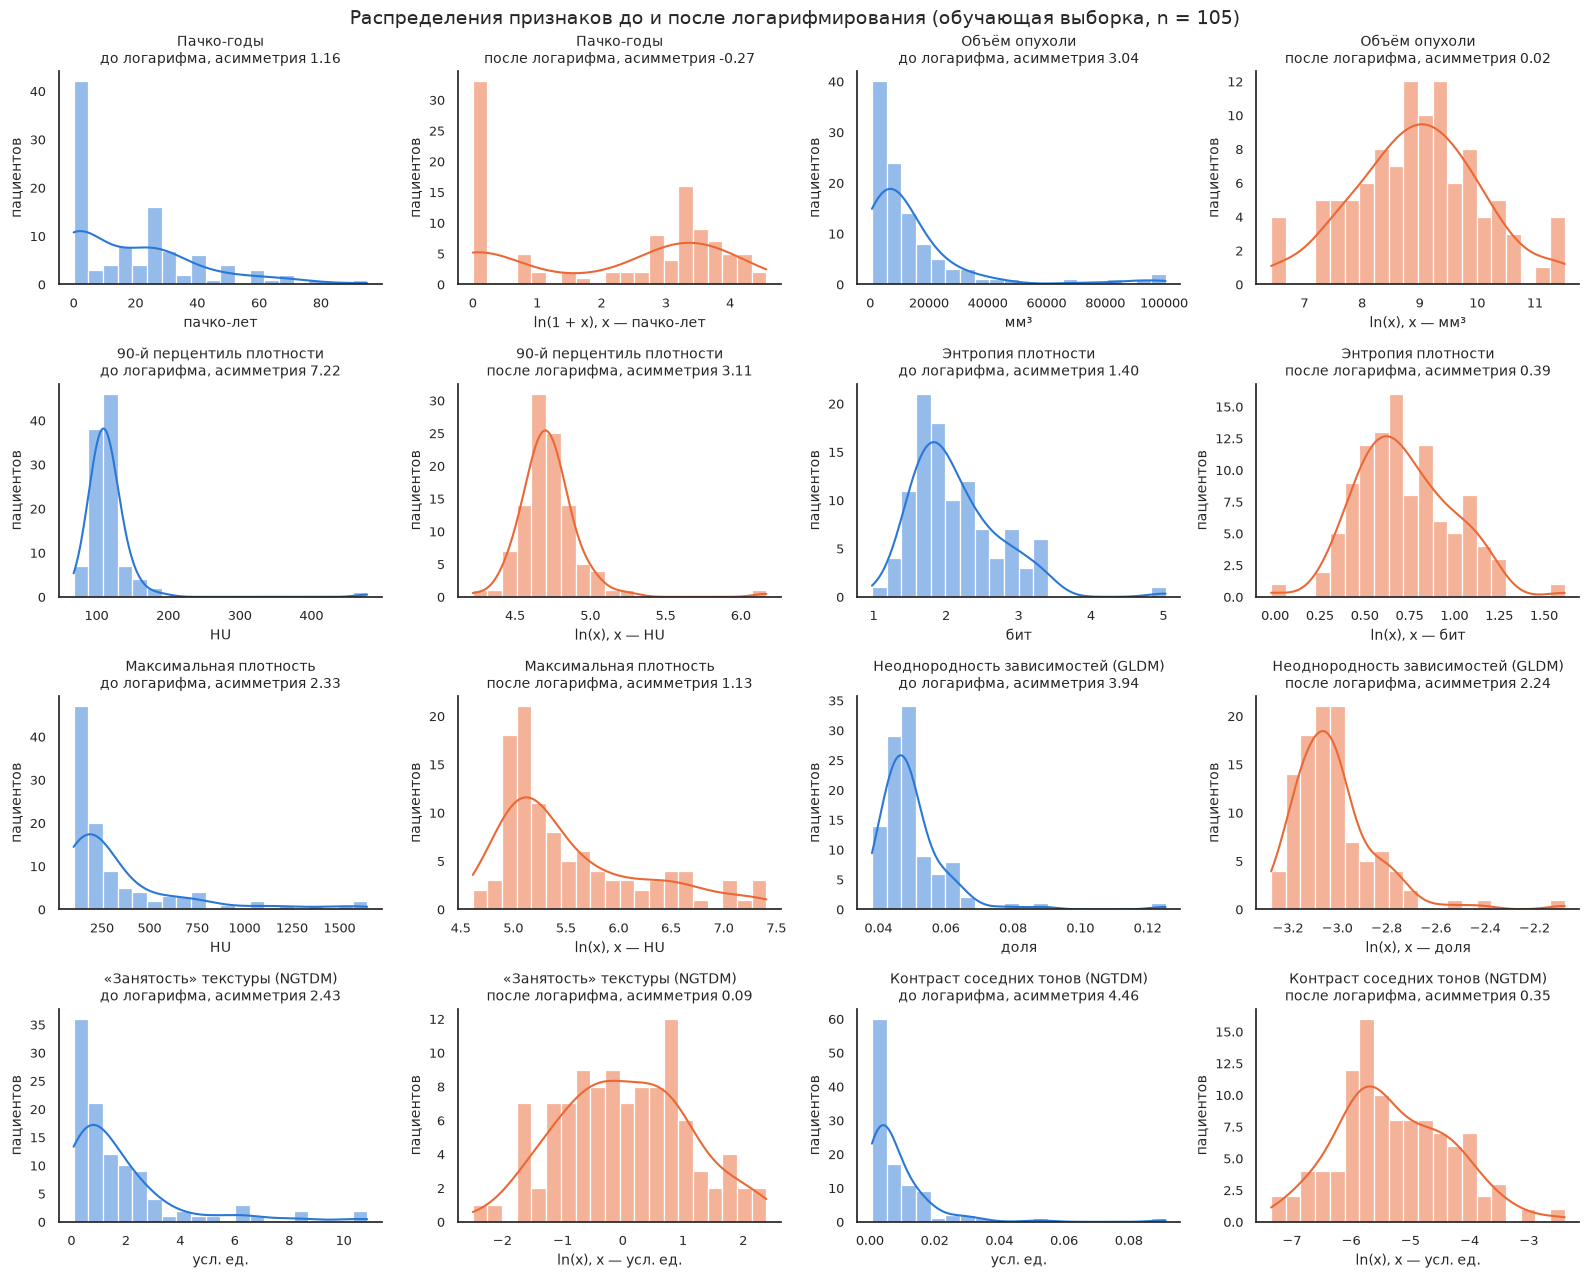

In [12]:
names = {
    "Smoking_Pack-Years": ("Пачко-годы", "пачко-лет"),
    "GTVp_shape_MeshVolume": ("Объём опухоли", "мм³"),
    "GTVp_firstorder_90Percentile": ("90-й перцентиль плотности", "HU"),
    "GTVp_firstorder_Entropy": ("Энтропия плотности", "бит"),
    "GTVp_firstorder_Maximum": ("Максимальная плотность", "HU"),
    "GTVp_gldm_DependenceNonUniformityNormalized": ("Неоднородность зависимостей (GLDM)", "доля"),
    "GTVp_ngtdm_Busyness": ("«Занятость» текстуры (NGTDM)", "усл. ед."),
    "GTVp_ngtdm_Contrast": ("Контраст соседних тонов (NGTDM)", "усл. ед."),
}

sns.set_theme(style="white", font_scale=0.85)
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax_pair, col in zip(axes.reshape(-1, 2), skewed):
    title, unit = names[col]
    for ax, values, color, stage, xlabel in [
        (ax_pair[0], before_log[col], "#2a78d6", "до логарифма", unit),
        (ax_pair[1], train[col], "#eb6834", "после логарифма", f"ln({'1 + ' if col in log_one else ''}x), x — {unit}"),
    ]:
        sns.histplot(values, bins=20, kde=True, color=color, edgecolor="white", ax=ax)
        ax.set_title(f"{title}\n{stage}, асимметрия {values.skew():.2f}", fontsize=10)
        ax.set_xlabel(xlabel)
        ax.set_ylabel("пациентов")
    sns.despine(ax=ax_pair[0]); sns.despine(ax=ax_pair[1])

fig.suptitle(f"Распределения признаков до и после логарифмирования (обучающая выборка, n = {len(train)})", fontsize=14)
fig.tight_layout()
plt.show()

In [13]:
ordinal_codes = {
    "N_category": {"0": 0, "1": 1, "2a": 2, "2b": 3, "2c": 4, "3": 5},
    "AJCC_Stage": {"I": 1, "II": 2, "III": 3, "IV": 4},
}
for df in (train, test):
    for col, codes in ordinal_codes.items():
        df[col] = df[col].astype(str).map(codes)

scaled = quant + ordinal
shift = train[scaled].mean()
scale = train[scaled].std()
for df in (train, test):
    df[scaled] = (df[scaled] - shift) / scale

pd.DataFrame({"сдвиг": shift, "масштаб": scale}).round(4)

,сдвиг,масштаб
Age_at_diagnosis,59.3714,9.0758
Smoking_Pack-Years,2.0848,1.6277
Total_prescribed_Radiation_treatment_dose,68.4381,2.3855
Dose_per_fraction,2.1325,0.1005
GTVp_shape_MeshVolume,8.9715,1.1007
GTVp_shape_Sphericity,0.6207,0.1018
GTVp_shape_Elongation,0.7184,0.1412
GTVp_shape_Flatness,0.5392,0.1341
GTVp_firstorder_10Percentile,44.1644,41.3803
GTVp_firstorder_90Percentile,4.7257,0.2123


## Кодирование категориальных признаков

In [14]:
binary_codes = {"Gender": {"Female": 0, "Male": 1},
                "Induction_Chemotherapy": {"N": 0, "Y": 1},
                "Concurrent_chemotherapy": {"N": 0, "Y": 1}}
for df in (train, test):
    for col, codes in binary_codes.items():
        df[col] = df[col].map(codes)

train[binary].mean().round(2)

Gender                     0.88
Induction_Chemotherapy     0.37
Concurrent_chemotherapy    0.70
dtype: float64

In [15]:
min_count = 5
levels = {}
for col in nominal:
    counts = train[col].value_counts()
    rare = counts[counts < min_count].index.tolist()
    common = counts[counts >= min_count].index.tolist()
    other = "Other" if "Other" in common else "other"
    if rare and other not in common:
        common.append(other)
    levels[col] = (common, other)
    print(col, counts.to_dict(), ", редкие:", rare)

Race {'White': 100, 'Black': 3, 'Hispanic': 2} , редкие: ['Black', 'Hispanic']
Tumor_side {'L': 57, 'R': 48} , редкие: []
Tumor_subsite {'BOT': 48, 'Tonsil': 40, 'Other': 7, 'GPS': 7, 'Soft_palate': 2, 'Pharyngeal_wall': 1} , редкие: ['Soft_palate', 'Pharyngeal_wall']
Smoking_status_at_diagnosis {'Former': 40, 'Never': 33, 'Current': 32} , редкие: []


In [16]:
new_columns = []
for col, (common, other) in levels.items():
    reference = train[col].where(train[col].isin(common), other).value_counts().idxmax()
    for df in (train, test):
        values = df[col].where(df[col].isin(common), other)
        for level in common:
            if level != reference:
                df[f"{col}_{level}"] = (values == level).astype(int)
    new_columns += [f"{col}_{level}" for level in common if level != reference]
    print(col, "опорная категория:", reference)

for df in (train, test):
    df.drop(columns=nominal, inplace=True)

new_columns

Race опорная категория: White
Tumor_side опорная категория: L
Tumor_subsite опорная категория: BOT
Smoking_status_at_diagnosis опорная категория: Former


['Race_other',
 'Tumor_side_R',
 'Tumor_subsite_Tonsil',
 'Tumor_subsite_Other',
 'Tumor_subsite_GPS',
 'Smoking_status_at_diagnosis_Never',
 'Smoking_status_at_diagnosis_Current']

## Подготовленные выборки

In [17]:
columns = ["Patient_ID", target] + [col for col in train.columns if col not in ["Patient_ID", target]]
train = train[columns]
test = test[columns]
train[target] = train[target].astype(int)
test[target] = test[target].astype(int)

train.to_csv("train.csv", index=False)
test.to_csv("test.csv", index=False)

saved = {name: pd.read_csv(f"{name}.csv") for name in ("train", "test")}
pd.DataFrame({name: {"пациентов": len(df), "исход 1": int(df[target].sum()), "признаков": df.shape[1] - 2}
              for name, df in saved.items()})

,train,test
пациентов,105,35
исход 1,9,3
признаков,35,35


In [18]:
features = saved["train"].columns[2:]
(saved["train"].columns == saved["test"].columns).all(), \
    all(pd.api.types.is_numeric_dtype(saved[name][col]) for name in saved for col in features), \
    saved["train"].isna().sum().sum() + saved["test"].isna().sum().sum()

(np.True_, True, np.int64(0))

Итого признаков:

In [19]:
list(features)

['Gender',
 'T_category',
 'N_category',
 'AJCC_Stage',
 'Pathological_grade',
 'Induction_Chemotherapy',
 'Concurrent_chemotherapy',
 'Age_at_diagnosis',
 'Smoking_Pack-Years',
 'Total_prescribed_Radiation_treatment_dose',
 'Dose_per_fraction',
 'GTVp_shape_MeshVolume',
 'GTVp_shape_Sphericity',
 'GTVp_shape_Elongation',
 'GTVp_shape_Flatness',
 'GTVp_firstorder_10Percentile',
 'GTVp_firstorder_90Percentile',
 'GTVp_firstorder_Entropy',
 'GTVp_firstorder_Kurtosis',
 'GTVp_firstorder_Maximum',
 'GTVp_firstorder_Minimum',
 'GTVp_glcm_Correlation',
 'GTVp_glcm_InverseVariance',
 'GTVp_gldm_DependenceNonUniformityNormalized',
 'GTVp_glszm_SizeZoneNonUniformityNormalized',
 'GTVp_ngtdm_Busyness',
 'GTVp_ngtdm_Contrast',
 'Pathological_grade_missing',
 'Race_other',
 'Tumor_side_R',
 'Tumor_subsite_Tonsil',
 'Tumor_subsite_Other',
 'Tumor_subsite_GPS',
 'Smoking_status_at_diagnosis_Never',
 'Smoking_status_at_diagnosis_Current']